# 07 黑马优购 - 分类与搜索


本篇是微信小程序**项目第 2 天**，承接 06 的 uni-app 起步、tabBar 与首页。原讲义顺序为“4. 分类 → 5. 搜索”：先实现左右独立滚动的三级分类，再封装搜索入口、开发搜索建议，最后保存搜索历史。

资料来自[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234)中“微信小程序项目/微信小程序项目-资料/day02.rar”。已读取本机下载的项目资料包 `day02 (2).rar`，包含 `学习目标.txt`、17 页 `uni-shop_day2.pdf`、商城 API 文档以及完成版 `uni-shop-2` 源码。代码换行同时对照同课程在线讲义的[分类](https://applet-base-api-t.itheima.net/docs-uni-shop/4.cate.html)与[搜索](https://applet-base-api-t.itheima.net/docs-uni-shop/5.search.html)，图片采用原课图片并内嵌在本笔记中。

| 文件 | 本天的改动 |
| --- | --- |
| `pages/cate/cate.vue` | 一级选中、二三级展示、滚动位置重置与分类跳转 |
| `components/my-search/my-search.vue` | 模拟搜索框、可配置属性与自定义点击事件 |
| `pages/home/home.vue` | 接入搜索入口，并实现吸顶 |
| `pages.json`、`subpkg/search/search.vue` | 注册搜索分包页，开发建议列表和搜索历史 |
| `components/uni-search-bar/uni-search-bar.vue` | 调整搜索栏背景与初始焦点 |

沿用课程 Vue 2 写法及第 1 天配置的 `uni.$http`、`uni.$showMsg()`、`uni-icons` 等组件。代码合并到标明的文件中，保留已有的 `data`、`onLoad`、`methods` 和样式；分步骤展示的对象片段不能另建重复的 `export default`。示例命令在课程项目根目录操作，本笔记不执行安装、Git 提交或推送。


## 一、分类页面的结构与滚动高度

### 1. 创建 cate 分支

在课程项目的 `master` 分支基础上创建分类功能分支：

```bash
git checkout -b cate
```

目标文件为 `pages/cate/cate.vue`。页面分为两部分：左侧选择一级分类，右侧显示当前一级分类下的二级标题和三级分类。两侧需要独立纵向滚动，所以使用两个 `scroll-view`，通过 Flex 横向排列。

先按原课放入静态条目，确认布局与滚动有效，之后再替换为接口数据：

```html
<template>
  <view>
    <view class="scroll-view-container">
      <!-- 左侧的滚动视图区域 -->
      <scroll-view class="left-scroll-view" scroll-y :style="{height: wh + 'px'}">
        <view class="left-scroll-view-item active">xxx</view>
        <view class="left-scroll-view-item">xxx</view>
        <view class="left-scroll-view-item">xxx</view>
        <view class="left-scroll-view-item">xxx</view>
        <view class="left-scroll-view-item">xxx</view>
        <view class="left-scroll-view-item">多复制一些节点，演示纵向滚动效果...</view>
      </scroll-view>
      <!-- 右侧的滚动视图区域 -->
      <scroll-view class="right-scroll-view" scroll-y :style="{height: wh + 'px'}">
        <view class="left-scroll-view-item">zzz</view>
        <view class="left-scroll-view-item">zzz</view>
        <view class="left-scroll-view-item">zzz</view>
        <view class="left-scroll-view-item">zzz</view>
        <view class="left-scroll-view-item">多复制一些节点，演示纵向滚动效果</view>
      </scroll-view>
    </view>
  </view>
</template>
```

`scroll-y` 开启纵向滚动，`:style` 为两个区域设置相同高度。静态条目足够多、内容超过容器高度时，应能分别拖动左右区域。


### 2. 动态计算可用高度

在 `pages/cate/cate.vue` 的 `data` 中定义 `wh`，在 `onLoad` 中读取设备信息：

```javascript
export default {
    data() {
      return {
        // 窗口的可用高度 = 屏幕高度 - navigationBar高度 - tabBar 高度
        wh: 0
      };
    },
    onLoad() {
      // 获取当前系统的信息
      const sysInfo = uni.getSystemInfoSync()
      // 为 wh 窗口可用高度动态赋值
      this.wh = sysInfo.windowHeight
    }
  }
```

`sysInfo.windowHeight` 是当前页面可用窗口的高度，返回单位为 `px`，所以样式绑定写成 `wh + 'px'`。两个 `scroll-view` 要有明确高度，才能在内部滚动。

原课此时直接使用 `windowHeight`；后面增加高 `50px` 的搜索组件后，再减去这 `50px`。不要再次从 `windowHeight` 中重复减去导航栏和 tabBar 的高度。


### 3. 设置一级分类和选中指示条的样式

在 `pages/cate/cate.vue` 的 `<style lang="scss">` 中加入：

```scss
.scroll-view-container {
  display: flex;

  .left-scroll-view {
    width: 120px;

    .left-scroll-view-item {
      line-height: 60px;
      background-color: #f7f7f7;
      text-align: center;
      font-size: 12px;

      // 激活项的样式
      &.active {
        background-color: #ffffff;
        position: relative;

        // 渲染激活项左侧的红色指示边线
        &::before {
          content: ' ';
          display: block;
          width: 3px;
          height: 30px;
          background-color: #c00000;
          position: absolute;
          left: 0;
          top: 50%;
          transform: translateY(-50%);
        }
      }
    }
  }
}
```

左侧宽 `120px`，每项行高 `60px`。普通项为浅灰背景，选中项通过 `.active` 改为白底。

`&.active` 指当前条目同时带有 `active` 类；`&::before` 在选中条目左侧生成宽 `3px`、高 `30px` 的红色指示条。`top: 50%` 配合 `translateY(-50%)` 使指示条垂直居中。


## 二、三级分类的数据与联动

### 1. 请求分类数据

在 `pages/cate/cate.vue` 的 `data` 中增加 `cateList: []`，并在原有 `onLoad` 中继续调用 `this.getCateList()`，保留计算 `wh` 的代码。新增请求方法放在 `methods`：

```javascript
export default {
  methods: {
    async getCateList() {
      // 发起请求
      const { data: res } = await uni.$http.get('/api/public/v1/categories')
      // 判断是否获取失败
      if (res.meta.status !== 200) return uni.$showMsg()
      // 转存数据
      this.cateList = res.message
    }
  }
}
```

分类接口为 `GET /api/public/v1/categories`，无需参数。响应 `data` 解构为 `res`；检查 `res.meta.status` 后，将 `res.message` 转存到 `cateList`。

| 字段或表达式 | 用途 |
| --- | --- |
| `cateList` | 全部一级分类的数组 |
| `item.cat_name` | 当前分类名称 |
| `item.children` | 当前分类的子分类数组 |
| `item.cat_id` | 分类 ID，用于列表页查询 |
| `item.cat_icon` | 三级分类的图片地址 |

数据的层级是：一级分类的 `children` 为二级分类；二级分类的 `children` 为三级分类。API 文档更新说明指出新版 `cat_icon` 返回完整图片 URL，配套源码直接使用该字段，不额外拼接旧示例中的相对图片路径。


### 2. 渲染一级分类并切换选中项

在 `data` 中新增 `active: 0`，使第一项默认选中。将左侧静态条目替换为：

```html
<block v-for="(item, i) in cateList" :key="i">
  <view :class="['left-scroll-view-item', i === active ? 'active' : '']" @click="activeChanged(i)">{{item.cat_name}}</view>
</block>
```

这个 `block` 放在左侧 `scroll-view` 内。`v-for` 遍历 `cateList`，展示 `item.cat_name`；`:class` 数组始终保留基础类，只在 `i === active` 时增加 `active`。

在 `methods` 中新增：

```javascript
export default {
  methods: {
    // 选中项改变的事件处理函数
    activeChanged(i) {
      this.active = i
    }
  }
}
```

点击一级分类将索引 `i` 传给 `activeChanged`。改变 `active` 后，白底与红色指示条应随点击项移动。下一步再让右侧内容跟随这个索引变化。


### 3. 初始化与更新二级分类

在 `data` 中新增 `cateLevel2: []`。修改 `getCateList()`：成功获取一级列表后，将第一项的子分类赋给右侧列表。

```javascript
async getCateList() {
  const { data: res } = await uni.$http.get('/api/public/v1/categories')
  if (res.meta.status !== 200) return uni.$showMsg()
  this.cateList = res.message
  // 为二级分类赋值
  this.cateLevel2 = res.message[0].children
}
```

再修改 `activeChanged()`，让点击新一级分类时重新赋值：

```javascript
activeChanged(i) {
  this.active = i
  // 为二级分类列表重新赋值
  this.cateLevel2 = this.cateList[i].children
}
```

原课按接口返回至少一项、且每个一级项具有 `children` 的数据结构编写。`active` 控制左侧选中状态，`cateLevel2` 控制右侧内容，两者在同一个点击处理函数中更新，页面就能联动。


### 4. 渲染二级分类标题

将右侧静态条目替换为二级分类循环：

```html
<!-- 右侧的滚动视图区域 -->
<scroll-view class="right-scroll-view" scroll-y :style="{height: wh + 'px'}">
  <view class="cate-lv2" v-for="(item2, i2) in cateLevel2" :key="i2">
    <view class="cate-lv2-title">/ {{item2.cat_name}} /</view>
  </view>
</scroll-view>
```

在页面的 SCSS 中加入：

```scss
.cate-lv2-title {
  font-size: 12px;
  font-weight: bold;
  text-align: center;
  padding: 15px 0;
}
```

每个二级分类显示一个居中的加粗标题，名称两边加 `/`。切换左侧分类后，右侧标题列表应换成该一级分类的 `children`。


### 5. 在二级分类下渲染三级分类

在每个 `.cate-lv2` 内、标题之后遍历 `item2.children`，显示三级分类图标与名称。右侧完整结构为：

```html
<!-- 右侧的滚动视图区域 -->
<scroll-view class="right-scroll-view" scroll-y :style="{height: wh + 'px'}">
  <view class="cate-lv2" v-for="(item2, i2) in cateLevel2" :key="i2">
    <view class="cate-lv2-title">/ {{item2.cat_name}} /</view>
    <!-- 动态渲染三级分类的列表数据 -->
    <view class="cate-lv3-list">
      <!-- 三级分类 Item 项 -->
      <view class="cate-lv3-item" v-for="(item3, i3) in item2.children" :key="i3">
        <!-- 图片 -->
        <image :src="item3.cat_icon"></image>
        <!-- 文本 -->
        <text>{{item3.cat_name}}</text>
      </view>
    </view>
  </view>
</scroll-view>
```

这里使用两层循环：外层 `item2` 是二级分类，内层 `item3` 是它的三级分类。图标使用 `item3.cat_icon`，文本使用 `item3.cat_name`。


在同一个 `<style lang="scss">` 中加入三级分类样式：

```scss
.cate-lv3-list {
  display: flex;
  flex-wrap: wrap;

  .cate-lv3-item {
    width: 33.33%;
    margin-bottom: 10px;
    display: flex;
    flex-direction: column;
    align-items: center;

    image {
      width: 60px;
      height: 60px;
    }

    text {
      font-size: 12px;
    }
  }
}
```

列表使用 Flex 并允许换行；每项宽 `33.33%`，因此一行展示三个三级分类。条目内部采用纵向排列，图标为 `60px × 60px`，文本字号 `12px`。

检查不同一级分类的数据是否正确，二级标题下的三级图标和名称是否对应，超过一屏的内容是否能在右侧独立滚动。


### 6. 切换分类时重置右侧滚动位置

如果右侧已经滚动到底部，再换一级分类，新内容会沿用旧的滚动位置。因此需要在切换时回到接近顶部的位置。

1. 在 `data` 中增加 `scrollTop: 0`。
2. 为右侧 `scroll-view` 增加 `:scroll-top="scrollTop"`，保留内部的二、三级分类结构。

原课用下面的空节点示意新增属性，实际页面中继续保留已有内容：

```html
<!-- 右侧的滚动视图区域 -->
<scroll-view class="right-scroll-view" scroll-y :style="{height: wh + 'px'}" :scroll-top="scrollTop"></scroll-view>
```

3. 将 `activeChanged()` 更新为：

```javascript
// 选中项改变的事件处理函数
activeChanged(i) {
  this.active = i
  this.cateLevel2 = this.cateList[i].children

  // 让 scrollTop 的值在 0 与 1 之间切换
  this.scrollTop = this.scrollTop === 0 ? 1 : 0

  // 可以简化为如下的代码：
  // this.scrollTop = this.scrollTop ? 0 : 1
}
```

`scrollTop` 在 `0` 与 `1` 之间切换，确保每次赋值都发生变化，让视图重新设置滚动位置。始终重复赋 `0` 可能不会触发新的更新；这也是原课没有直接写 `this.scrollTop = 0` 的原因。

验证时先把右侧滚动到下面，连续切换多个一级分类，右侧每次都应回到顶部附近。


### 7. 点击三级分类进入商品列表

在三级分类的条目上增加点击事件，传入当前三级分类对象：

```html
<view class="cate-lv3-item" v-for="(item3, i3) in item2.children" :key="i3" @click="gotoGoodsList(item3)">
  <image :src="item3.cat_icon"></image>
  <text>{{item3.cat_name}}</text>
</view>
```

在 `methods` 中新增：

```javascript
// 点击三级分类项跳转到商品列表页面
gotoGoodsList(item3) {
  uni.navigateTo({
    url: '/subpkg/goods_list/goods_list?cid=' + item3.cat_id
  })
}
```

商品列表已经在 06 注册到 `subpkg`，这里通过普通页面导航 `uni.navigateTo()` 打开，并以 `cid` 参数传入 `cat_id`。检查点击不同三级分类后，列表页路径中的 `cid` 是否相应变化。本天只接好分类入口，商品列表内部的数据展示属于后续课程。


### 8. 提交并合并 cate 分支

在课程项目根目录按原课顺序操作：

```bash
git add .
git commit -m "完成了分类页面的开发"
git push -u origin cate
git checkout master
git merge cate
git push
git branch -d cate
```

先提交分类功能并推送 `cate`，再切回 `master` 合并并推送，最后删除已经合并的本地功能分支。完成这一步后，再基于 `master` 开发搜索。


## 三、自定义搜索入口组件

### 1. 创建 search 分支和 my-search 组件

在课程项目根目录创建搜索功能分支：

```bash
git checkout -b search
```

在 HBuilderX 的项目根目录 `components` 上右键，选择“新建组件”，组件名填写 `my-search`，选择 SCSS 模板并勾选“创建同名目录”。创建后的文件为 `components/my-search/my-search.vue`。

在 `pages/cate/cate.vue` 的根 `view` 中、左右滚动容器之前，直接使用 `<my-search></my-search>`。

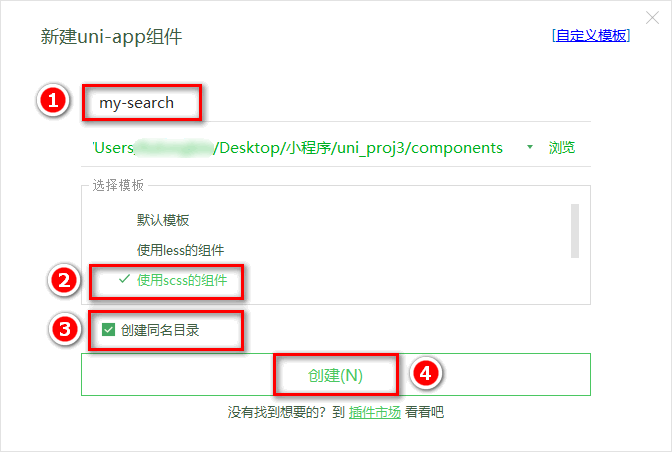


### 2. 用 view 模拟搜索框外观

在 `components/my-search/my-search.vue` 中定义模板：

```html
<template>
  <view class="my-search-container">
    <!-- 使用 view 组件模拟 input 输入框的样式 -->
    <view class="my-search-box">
      <uni-icons type="search" size="17"></uni-icons>
      <text class="placeholder">搜索</text>
    </view>
  </view>
</template>
```

加入 SCSS 样式：

```scss
.my-search-container {
  background-color: #c00000;
  height: 50px;
  padding: 0 10px;
  display: flex;
  align-items: center;
}

.my-search-box {
  height: 36px;
  background-color: #ffffff;
  border-radius: 15px;
  width: 100%;
  display: flex;
  align-items: center;
  justify-content: center;

  .placeholder {
    font-size: 15px;
    margin-left: 5px;
  }
}
```

外层红色容器高 `50px`，左右内边距 `10px`；内部白色搜索框高 `36px`，通过 Flex 将搜索图标和“搜索”文字放在中央。

> `my-search` 使用 `view` 模拟输入框样式，并不会渲染真正的 `input`。它是首页和分类页的可点击搜索入口；输入关键词在独立的搜索页面完成。


### 3. 搜索组件占用 50px，重新计算分类区高度

在 `pages/cate/cate.vue` 中，把原来的 `this.wh = sysInfo.windowHeight` 改为减去搜索组件高度，同时保留获取分类数据的调用。配套完成版的 `onLoad` 为：

```javascript
onLoad() {
  const sysInfo = uni.getSystemInfoSync()
  this.wh = sysInfo.windowHeight - 50

  this.getCateList()
}
```

两个 `scroll-view` 继续使用 `wh + 'px'`。分类页的搜索入口位于滚动容器之外，两侧列表在它下面独立滚动，不需要把入口塞到某一侧的 `scroll-view` 中。


### 4. 用 props 开放背景颜色和圆角

在 `components/my-search/my-search.vue` 的组件对象中新增 `props`：

```javascript
export default {
  props: {
    // 背景颜色
    bgcolor: {
      type: String,
      default: '#C00000'
    },
    // 圆角尺寸
    radius: {
      type: Number,
      // 单位是 px
      default: 18
    }
  }
}
```

再将模板中的背景色、圆角改为动态样式：

```html
<view class="my-search-container" :style="{'background-color': bgcolor}">
  <view class="my-search-box" :style="{'border-radius': radius + 'px'}">
    <uni-icons type="search" size="17"></uni-icons>
    <text class="placeholder">搜索</text>
  </view>
</view>
```

移除或注释 SCSS 中 `.my-search-container` 写死的 `background-color` 和 `.my-search-box` 写死的 `border-radius`，其他高度、布局、字号样式继续保留。以后这两项由 `props` 控制。

| 属性 | 类型 | 默认值 | 绑定到哪里 |
| --- | --- | --- | --- |
| `bgcolor` | `String` | `#C00000` | 外层容器背景 |
| `radius` | `Number` | `18`，单位 px | 内部白色框圆角 |

配套分类页的测试示例为 `<my-search :bgcolor="'pink'" :radius="3"></my-search>`。使用 `:radius="3"` 传入数字，组件内部再补上 `'px'`。测试后恢复默认属性即可。


### 5. 通过自定义 click 事件通知页面

原讲义在内部 `.my-search-box` 上绑定 `@click="searchBoxHandler"`，并在组件 `methods` 中触发对外的事件：

```javascript
export default {
  methods: {
    // 点击了模拟的 input 输入框
    searchBoxHandler() {
      // 触发外界通过 @click 绑定的 click 事件处理函数
      this.$emit('click')
    }
  }
}
```

在分类页面中监听这个事件：

```html
<!-- 使用自定义的搜索组件 -->
<my-search @click="gotoSearch"></my-search>
```

再在 `pages/cate/cate.vue` 的 `methods` 中新增导航方法：

```javascript
gotoSearch() {
  uni.navigateTo({
    url: '/subpkg/search/search'
  })
}
```

点击入口 → 组件调用 `this.$emit('click')` → 页面执行 `gotoSearch()` → 打开搜索分包页。页面决定跳转行为，组件只发出点击通知。

配套完成版将内部点击监听放在外层 `.my-search-container`，使整条搜索区域都可以点击。下方保留配套完成版，两种绑定位置任选其一，避免内外同时绑定导致重复触发。


### 6. my-search 完成版

文件：`components/my-search/my-search.vue`。它同时包含动态属性、模拟输入框样式与对外点击事件：

```vue
<template>
  <view class="my-search-container" :style="{ 'background-color': bgcolor }" @click="searchBoxHandler">
    <view class="my-search-box" :style="{ 'border-radius': radius + 'px' }">
      <!-- 使用 uni-ui 提供的图标组件 -->
      <uni-icons type="search" size="17"></uni-icons>
      <text class="placeholder">搜索</text>
    </view>
  </view>
</template>

<script>
  export default {
    props: {
      // 背景颜色
      bgcolor: {
        type: String,
        default: '#C00000'
      },
      // 圆角尺寸
      radius: {
        type: Number,
        default: 18 // px
      }
    },
    data() {
      return {

      }
    },
    methods: {
      searchBoxHandler() {
        this.$emit('click')
      }
    }
  }
</script>

<style lang="scss">
  .my-search-container {
    height: 50px;
    // background-color: #C00000;
    display: flex;
    align-items: center;
    padding: 0 10px;

    .my-search-box {
      height: 36px;
      background-color: #FFFFFF;
      // border-radius: 18px;
      width: 100%;
      display: flex;
      justify-content: center;
      align-items: center;

      .placeholder {
        font-size: 15px;
        margin-left: 5px;
      }
    }
  }
</style>
```


### 7. 接入首页并实现吸顶

在 `pages/home/home.vue` 的根 `view` 中、轮播区域之前加入：

```html
<!-- 使用自定义的搜索组件 -->
<view class="search-box">
  <my-search @click="gotoSearch"></my-search>
</view>
```

在首页已有 `methods` 中加入前面的 `gotoSearch()`，导航地址仍为 `/subpkg/search/search`。在首页的 SCSS 中新增：

```scss
.search-box {
  // 设置定位效果为“吸顶”
  position: sticky;
  // 吸顶的“位置”
  top: 0;
  // 提高层级，防止被轮播图覆盖
  z-index: 999;
}
```

`position: sticky` 让区域滚到 `top: 0` 后贴在顶部；`z-index: 999` 提高层级，防止被轮播图覆盖。首页向下滚动到楼层区域时，搜索入口应仍停在页面内容顶部；点击后进入同一个搜索页。


## 四、搜索建议：输入、防抖与结果展示

### 1. 注册搜索分包页面

配套源码中的搜索文件为 `subpkg/search/search.vue`。沿用 06 的创建方式，在 `subpkg` 下新建 `search`，并注册到根目录 `pages.json` 的已有 `subPackages` 中：

```json
{
  "subPackages": [
    {
      "root": "subpkg",
      "pages": [
        {
          "path": "goods_detail/goods_detail",
          "style": {}
        },
        {
          "path": "goods_list/goods_list",
          "style": {}
        },
        {
          "path": "search/search",
          "style": {}
        }
      ]
    }
  ]
}
```

此片段和根节点 `pages` 平级；保留已有的详情页、列表页，增加 `search/search` 记录。分包内的 `path` 相对于 `subpkg`，不重复添加 `subpkg/`，导航使用完整路径 `/subpkg/search/search`。


### 2. 使用真正的 uni-search-bar 输入框

在 `subpkg/search/search.vue` 中加入：

```html
<view class="search-box">
  <!-- 使用 uni-ui 提供的搜索组件 -->
  <uni-search-bar @input="input" :radius="100" cancelButton="none"></uni-search-bar>
</view>
```

`uni-search-bar` 来自配套的 uni-ui 组件。`:radius="100"` 设置圆角，`cancelButton="none"` 隐藏取消按钮，`@input="input"` 监听输入变化。

最初在页面 `methods` 中通过以下处理函数观察输入值：

```javascript
export default {
  methods: {
    input(e) {
      // e.value 是最新的搜索内容
      console.log(e.value)
    }
  }
}
```

事件对象的 `e.value` 就是最新输入内容。这里是自定义组件发出的输入事件，因此按组件定义读取 `e.value`；后续用防抖逻辑替换这个日志处理函数。

搜索页也为 `.search-box` 设置 `position: sticky; top: 0; z-index: 999;`，确保搜索建议列表滚动时输入区域保持在顶部。


### 3. 修改搜索栏背景色

原课直接调整配套组件文件 `components/uni-search-bar/uni-search-bar.vue` 的 `.uni-searchbar` 样式，将默认白色背景改为红色：

```css
.uni-searchbar {
  /* #ifndef APP-NVUE */
  display: flex;
  /* #endif */
  flex-direction: row;
  position: relative;
  padding: 16rpx;
  /* 将默认的 #FFFFFF 改为 #C00000 */
  background-color: #c00000;
}
```

改的是外层搜索栏背景，不是输入框的 `bgColor` 属性。保留原组件其他样式和条件编译注释。运行后，搜索页顶部应与商城主色保持一致。


### 4. 初次进入搜索页时自动获取焦点

在同一个 `components/uni-search-bar/uni-search-bar.vue` 中，将 `data` 的 `show`、`showSync` 初始值都从 `false` 改为 `true`：

```javascript
export default {
  data() {
    return {
      show: true,
      showSync: true,
      searchVal: ""
    }
  }
}
```

配套组件的真实输入节点为 `<input v-if="show" :focus="showSync" ...>`：`show` 控制输入节点显示，`showSync` 控制焦点。两项设为 `true` 后，页面进入时就显示输入框并请求焦点。

原课要求用手机扫码预览检查真机效果，确认进入搜索页时可以直接输入。这个修改针对课程附带的组件版本。


### 5. 实现 500 毫秒防抖

搜索建议无需在每次按键时立刻请求。防抖是连续输入时不断重新计时，等输入停止一段时间后再处理最后一次内容。

在 `subpkg/search/search.vue` 的 `data` 中新增 `timer: null` 和 `kw: ''`。将页面 `methods` 中的 `input()` 更新为配套完成版：

```javascript
input(e) {
  clearTimeout(this.timer)

  this.timer = setTimeout(() => {
    this.kw = e.value
    this.getSearchList()
  }, 500)
}
```

每次输入先清除上一次延时器，再创建新延时器并保存到 `this.timer`。如果 `500` 毫秒内又输入，之前那次处理被取消；只有最后一次等待满 `500` 毫秒，才把 `e.value` 赋给 `kw` 并查询建议。

检查时连续快速输入几个字符，应在停顿后才发起查询，而不是每个字符都立即发请求。这是延后执行最后一次输入处理，与持续输入期间固定间隔执行不同。


### 6. 根据关键词请求搜索建议

在搜索页 `data` 中新增 `searchResults: []`。`getSearchList()` 放在 `methods` 中，初始查询逻辑按讲义如下：

```javascript
// 根据搜索关键词，搜索商品建议列表
async getSearchList() {
  // 判断关键词是否为空
  if (this.kw === '') {
    this.searchResults = []
    return
  }
  // 发起请求，获取搜索建议列表
  const { data: res } = await uni.$http.get('/api/public/v1/goods/qsearch', { query: this.kw })
  if (res.meta.status !== 200) return uni.$showMsg()
  this.searchResults = res.message
}
```

| 项目 | 内容 |
| --- | --- |
| 请求方法 | GET |
| 接口 | `/api/public/v1/goods/qsearch` |
| 查询参数 | `{ query: this.kw }` |
| 成功判断 | `res.meta.status === 200` |
| 建议数组 | `res.message` |
| 条目字段 | `goods_id`、`goods_name` |

空字符串时先清空 `searchResults` 并 `return`，不发出无关键词请求。配套完成版使用 `this.kw.length === 0`，对这里的字符串关键词意义相同。删除输入内容并等待防抖结束后，建议列表也应清空。

本篇沿用第 1 天 `main.js` 配置的请求对象与提示方法，不重新配置另一套请求方式。


### 7. 展示搜索建议并进入详情页

在搜索输入区域之后加入建议列表，以下使用配套源码的传参方式：

```html
<!-- 搜索建议列表 -->
<view class="sugg-list">
  <view class="sugg-item" v-for="(item, i) in searchResults" :key="i" @click="gotoDetail(item)">
    <view class="goods-name">{{item.goods_name}}</view>
    <uni-icons type="arrowright" size="16"></uni-icons>
  </view>
</view>
```

在搜索页 `methods` 中新增：

```javascript
gotoDetail(item) {
  uni.navigateTo({
    url: '/subpkg/goods_detail/goods_detail?goods_id=' + item.goods_id
  })
}
```

条目显示 `goods_name`，右侧用 `uni-icons` 的 `arrowright` 表示可进入详情。点击时传入整个 `item`，方法读取 `item.goods_id` 拼接详情地址。

原讲义使用 `gotoDetail(item.goods_id)`，相应方法接收 `goods_id`；配套源码使用 `gotoDetail(item)`，方法接收对象。两种方式都可以，但模板和方法必须配套，不能只改其中一处。


### 8. 单行文字溢出时显示省略号

在 `subpkg/search/search.vue` 的 SCSS 中加入建议列表样式：

```scss
.sugg-list {
  padding: 0 5px;

  .sugg-item {
    font-size: 12px;
    padding: 13px 0;
    border-bottom: 1px solid #efefef;
    display: flex;
    align-items: center;
    justify-content: space-between;

    .goods-name {
      // 文字不允许换行（单行文本）
      white-space: nowrap;
      // 溢出部分隐藏
      overflow: hidden;
      // 文本溢出后，使用 ... 代替
      text-overflow: ellipsis;
      margin-right: 3px;
    }
  }
}
```

每一行用 Flex 将商品名与右箭头排列，商品名过长时使用省略号：

| 样式 | 作用 |
| --- | --- |
| `white-space: nowrap` | 文本保持单行，不换行 |
| `overflow: hidden` | 隐藏超出区域的文字 |
| `text-overflow: ellipsis` | 用省略号提示被截断的内容 |

三项共同作用，不能只写 `text-overflow`。检查长商品名应显示成单行，右侧箭头仍可见，点击整行后参数对应当前商品。


## 五、搜索历史：展示、排序、去重与存储

### 1. 先使用假数据搭建结构

原课先在 `subpkg/search/search.vue` 的 `data` 中增加 `historyList: ['a', 'app', 'apple']`，用于检查显示样式。搜索历史包含标题、清空图标和关键词标签：

```html
<!-- 搜索历史 -->
<view class="history-box">
  <!-- 标题区域 -->
  <view class="history-title">
    <text>搜索历史</text>
    <uni-icons type="trash" size="17"></uni-icons>
  </view>
  <!-- 列表区域 -->
  <view class="history-list">
    <uni-tag :text="item" v-for="(item, i) in historyList" :key="i"></uni-tag>
  </view>
</view>
```

`uni-tag` 的 `text` 属性绑定当前关键词，通过 `v-for` 生成标签。此时使用的是临时数据，接下来改为记录真实的输入关键词，最终默认值改回空数组。


在同一个搜索页的 SCSS 中加入：

```scss
.history-box {
  padding: 0 5px;

  .history-title {
    display: flex;
    justify-content: space-between;
    align-items: center;
    height: 40px;
    font-size: 13px;
    border-bottom: 1px solid #efefef;
  }

  .history-list {
    display: flex;
    flex-wrap: wrap;

    .uni-tag {
      margin-top: 5px;
      margin-right: 5px;
    }
  }
}
```

标题行高 `40px`，文字与垃圾桶图标分布在两侧。关键词列表使用 Flex 并换行，每个标签保留上、右 `5px` 的间距，避免一排放不下时溢出。


### 2. 按结果数组决定显示建议还是历史

为前面两个区域增加 `v-if` 与 `v-else`：

```html
<!-- 搜索建议列表 -->
<view class="sugg-list" v-if="searchResults.length !== 0">
  <!-- 省略其它代码... -->
</view>

<!-- 搜索历史 -->
<view class="history-box" v-else>
  <!-- 省略其它代码... -->
</view>
```

当 `searchResults.length !== 0` 时显示搜索建议，隐藏历史；长度为 `0` 时显示历史，隐藏建议。示例省略的是两个区域内部原有的条目，实际使用时保留它们，并让 `v-else` 紧邻对应的 `v-if`。

判断依据是**结果数组长度**。因此清空输入后会回到历史区域；输入有内容但查询结果为空时，也显示历史，这是本课的页面规则。


### 3. 查询成功后保存关键词

在 `getSearchList()` 完成成功判断、更新 `searchResults` 之后，调用 `this.saveSearchHistory()`。最初的保存方法仅将 `kw` 追加到数组末尾：

```javascript
saveSearchHistory() {
  this.historyList.push(this.kw)
}
```

这一步说明历史记录的来源：成功查询时保存当前关键词，不是每次按键立即保存。原课接着指出两类问题：新关键词在数组末尾，页面希望最新词排前面；重复搜索同一个词，会产生重复记录。


### 4. 复制数组再反转，最新关键词排在前面

搜索页新增计算属性，和 `data`、`methods` 平级。下方沿用配套源码的命名 `histories`：

```javascript
export default {
  computed: {
    histories() {
      return [...this.historyList].reverse()
    }
  }
}
```

将历史标签的遍历数据改为计算属性：

```html
<uni-tag :text="item" v-for="(item, i) in histories" :key="i"></uni-tag>
```

`reverse()` 会直接修改被调用的数组，所以先用 `[...this.historyList]` 创建新数组，再反转副本。原始 `historyList` 仍按保存顺序维护，页面用反转后的计算结果展示，避免计算属性改变原数组。

讲义将计算属性命名为 `historys`，配套源码为 `histories`；本篇后续统一使用 `histories`，模板名称也同步。


### 5. 用 Set 去重，并把再次搜索的旧词移到末尾

用以下方法替换最初的 `push` 写法：

```javascript
// 保存搜索关键词为历史记录
saveSearchHistory() {
  // this.historyList.push(this.kw)

  // 1. 将 Array 数组转化为 Set 对象
  const set = new Set(this.historyList)
  // 2. 调用 Set 对象的 delete 方法，移除对应的元素
  set.delete(this.kw)
  // 3. 调用 Set 对象的 add 方法，向 Set 中添加元素
  set.add(this.kw)
  // 4. 将 Set 对象转化为 Array 数组
  this.historyList = Array.from(set)
}
```

`Set` 中的值唯一，并保留插入顺序。先由 `historyList` 创建集合，再删除当前词、重新添加，最后转回数组。这样既消除重复，又把本次搜索词放到保存数组末尾；反转展示后，它就排在页面最前面。

**理解示例：**若保存数组为 `['a', 'app', 'apple']`，再次搜索 `app`，删除再添加后变为 `['a', 'apple', 'app']`，展示顺序为 `['app', 'apple', 'a']`。这只是对原课算法的说明，不是运行输出。

只调用 `set.add(this.kw)` 可以防止新增重复项，但旧值不会因此改变插入位置，所以不能省掉前面的 `delete()`。


### 6. 持久化保存，重新进入时恢复历史

仅保存在 `data` 中，页面重新加载后就丢失。将 `saveSearchHistory()` 更新为：

```javascript
// 保存搜索关键词为历史记录
saveSearchHistory() {
  const set = new Set(this.historyList)
  set.delete(this.kw)
  set.add(this.kw)
  this.historyList = Array.from(set)
  // 调用 uni.setStorageSync(key, value) 将搜索历史记录持久化存储到本地
  uni.setStorageSync('kw', JSON.stringify(this.historyList))
}
```

用 `JSON.stringify()` 把历史数组转成 JSON 字符串，通过 `uni.setStorageSync('kw', ...)` 保存。这里 `kw` 是本地存储的键名，保存的内容是整个历史数组，并非只保存最新一个词。

将 `data.historyList` 初始值改为 `[]`，移除演示假数据，并在搜索页 `onLoad` 中恢复：

```javascript
onLoad() {
  this.historyList = JSON.parse(uni.getStorageSync('kw') || '[]')
}
```

第一次没有存储内容时，`|| '[]'` 提供合法的空数组字符串，`JSON.parse()` 将字符串还原为数组。保存与读取配成一组：数组 → JSON 字符串 → 本地存储 → JSON 字符串 → 数组。

退出搜索页并再次进入后，之前搜索过的关键词应仍存在，最新使用的词显示在前面。


### 7. 清空页面数据和本地历史

配套源码的清空方法名为 `clean`，在垃圾桶图标上绑定：

```html
<uni-icons type="trash" size="17" @click="clean"></uni-icons>
```

在搜索页 `methods` 中新增：

```javascript
clean() {
  this.historyList = []
  uni.setStorageSync('kw', '[]')
}
```

清空 `historyList` 会立即更新界面；同时把存储键 `kw` 写为 `'[]'`，让下次进入时也读到空数组。只清页面数据，旧记录会在下一次 `onLoad` 中重新出现。

原讲义将方法命名为 `cleanHistory`，本篇沿用配套源码的 `clean`，图标事件和方法名保持一致。检查清空后当前页面与重新进入后的页面都没有旧关键词。


### 8. 点击历史关键词进入商品列表

为历史标签增加点击事件，传入当前关键词字符串：

```html
<uni-tag :text="item" v-for="(item, i) in histories" :key="i" @click="gotoGoodsList(item)"></uni-tag>
```

在搜索页 `methods` 中新增：

```javascript
gotoGoodsList(kw) {
  uni.navigateTo({
    url: '/subpkg/goods_list/goods_list?query=' + kw
  })
}
```

历史记录进入商品列表时传 `query`，分类页进入商品列表时传 `cid`，搜索建议进入商品详情时传 `goods_id`。它们使用的页面与参数用途不同：

| 入口 | 目标页面 | 参数 |
| --- | --- | --- |
| 分类页的三级分类 | `/subpkg/goods_list/goods_list` | `cid=分类ID` |
| 搜索建议条目 | `/subpkg/goods_detail/goods_detail` | `goods_id=商品ID` |
| 搜索历史标签 | `/subpkg/goods_list/goods_list` | `query=关键词` |

本课这里只完成导航与传参，商品列表内部如何按关键词获取数据属于后续课程。


### 9. 提交并合并 search 分支

在课程项目根目录，检查搜索入口、建议列表与历史记录后，按原课顺序保存功能：

```bash
git add .
git commit -m "完成了搜索功能的开发"
git push -u origin search
git checkout master
git merge search
git push
git branch -d search
```

上述命令展示的是课程项目流程。本篇没有在当前笔记仓库进行分支切换、提交或远程推送。


## 六、完成版对照与验证

### 1. 分类页面的逻辑合并结果

文件：`pages/cate/cate.vue`。下方为配套完成版 `<script>` 的内容，包含搜索组件加入后的 `wh` 计算，以及分类联动、滚动重置和两类跳转：

```javascript
export default {
    data() {
      return {
        // 当前设备可用的高度
        wh: 0,
        cateList: [],
        active: 0,
        // 二级分类的列表
        cateLevel2: [],
        scrollTop: 0
      };
    },
    onLoad() {
      const sysInfo = uni.getSystemInfoSync()
      this.wh = sysInfo.windowHeight - 50

      this.getCateList()
    },
    methods: {
      // 获取分类列表的数据
      async getCateList() {
        const { data: res } = await uni.$http.get('/api/public/v1/categories')
        if (res.meta.status !== 200) return uni.$showMsg()
        this.cateList = res.message

        // 为二级分类赋值
        this.cateLevel2 = res.message[0].children
      },
      activeChanged(i) {
        this.active = i

        // 重新为二级分类赋值
        this.cateLevel2 = this.cateList[i].children

        this.scrollTop = this.scrollTop === 0 ? 1 : 0
      },
      // 跳转到商品列表页面
      gotoGoodsList(item) {
        uni.navigateTo({
          url: '/subpkg/goods_list/goods_list?cid=' + item.cat_id
        })
      },
      gotoSearch() {
        uni.navigateTo({
          url: '/subpkg/search/search'
        })
      }
    }
  }
```

模板要继续保留：顶部 `my-search @click="gotoSearch"`，左侧一级分类的 `activeChanged(i)`，右侧 `:scroll-top="scrollTop"`，三级分类的 `gotoGoodsList(item3)`。两侧的高度都使用 `wh`。


### 2. 搜索页面完成版

文件：`subpkg/search/search.vue`。下方保留配套完成版，核对 `input` 的延时调用、成功查询后的 `saveSearchHistory()`、`histories` 与 `clean` 的模板对应关系：

```vue
<template>
  <view>
    <view class="search-box">
      <uni-search-bar @input="input" :radius="100" cancelButton="none"></uni-search-bar>
    </view>

    <!-- 搜索建议列表 -->
    <view class="sugg-list" v-if="searchResults.length !== 0">
      <view class="sugg-item" v-for="(item, i) in searchResults" :key="i" @click="gotoDetail(item)">
        <view class="goods-name">{{item.goods_name}}</view>
        <uni-icons type="arrowright" size="16"></uni-icons>
      </view>
    </view>

    <!-- 搜索历史 -->
    <view class="history-box" v-else>
      <!-- 标题区域 -->
      <view class="history-title">
        <text>搜索历史</text>
        <uni-icons type="trash" size="17" @click="clean"></uni-icons>
      </view>
      <!-- 列表区域 -->
      <view class="history-list">
        <uni-tag :text="item" v-for="(item, i) in histories" :key="i" @click="gotoGoodsList(item)"></uni-tag>
      </view>
    </view>
  </view>
</template>

<script>
  export default {
    data() {
      return {
        timer: null,
        kw: '',
        // 搜索的结果列表
        searchResults: [],
        // 搜索历史的数组
        historyList: []
      };
    },
    onLoad() {
      this.historyList = JSON.parse(uni.getStorageSync('kw') || '[]')
    },
    methods: {
      // input 输入事件的处理函数
      input(e) {
        clearTimeout(this.timer)

        this.timer = setTimeout(() => {
          this.kw = e.value
          this.getSearchList()
        }, 500)
      },
      async getSearchList() {
        // 判断搜索关键词是否为空
        if (this.kw.length === 0) {
          this.searchResults = []
          return
        }

        const { data: res } = await uni.$http.get('/api/public/v1/goods/qsearch', { query: this.kw })
        if (res.meta.status !== 200) return uni.$showMsg()
        this.searchResults = res.message

        this.saveSearchHistory()
      },
      gotoDetail(item) {
        uni.navigateTo({
          url: '/subpkg/goods_detail/goods_detail?goods_id=' + item.goods_id
        })
      },
      saveSearchHistory() {
        // this.historyList.push(this.kw)

        const set = new Set(this.historyList)
        set.delete(this.kw)
        set.add(this.kw)

        this.historyList = Array.from(set)

        // 对搜索历史数据，进行持久化的存储
        uni.setStorageSync('kw', JSON.stringify(this.historyList))
      },
      clean() {
        this.historyList = []
        uni.setStorageSync('kw', '[]')
      },
      gotoGoodsList(kw) {
        uni.navigateTo({
          url: '/subpkg/goods_list/goods_list?query=' + kw
        })
      }
    },
    computed: {
      histories() {
        return [...this.historyList].reverse()
      }
    }
  }
</script>

<style lang="scss">
  .search-box {
    position: sticky;
    top: 0;
    z-index: 999;
  }

  .sugg-list {
    padding: 0 5px;

    .sugg-item {
      display: flex;
      align-items: center;
      justify-content: space-between;
      font-size: 12px;
      padding: 13px 0;
      border-bottom: 1px solid #efefef;

      .goods-name {
        white-space: nowrap;
        overflow: hidden;
        text-overflow: ellipsis;
        margin-right: 3px;
      }
    }
  }

  .history-box {
    padding: 0 5px;

    .history-title {
      display: flex;
      justify-content: space-between;
      height: 40px;
      align-items: center;
      font-size: 13px;
      border-bottom: 1px solid #efefef;
    }

    .history-list {
      display: flex;
      flex-wrap: wrap;

      .uni-tag {
        margin-top: 5px;
        margin-right: 5px;
      }
    }
  }
</style>
```


### 3. 跟课验证与本天完成范围

| 验证操作 | 应看到的效果 |
| --- | --- |
| 打开分类页 | 第一项选中，右侧显示对应的二、三级分类 |
| 分别滚动两侧列表 | 左右各自滚动，搜索入口保留在顶部 |
| 右侧滚到底部后切换一级分类 | 右侧数据更换，并回到顶部附近 |
| 点击三级分类 | 列表页 URL 携带正确 `cid` |
| 从首页或分类页点击搜索入口 | 打开同一个搜索分包页 |
| 滚动首页 | 搜索入口吸顶且不被轮播覆盖 |
| 手机上进入搜索页 | 输入框可以直接输入，检查自动焦点效果 |
| 连续输入再停顿 | 停止输入 500 毫秒后查询建议 |
| 查看长商品名并点击建议 | 单行省略，打开对应 `goods_id` 的详情页 |
| 删除全部输入内容 | 清空建议列表并展示历史区域 |
| 重复搜索一个旧关键词 | 历史不重复，最新使用的词排在前面 |
| 离开并重新进入搜索页 | 历史从本地存储恢复 |
| 清空历史后重新进入 | 旧历史不恢复 |
| 点击历史标签 | 商品列表 URL 携带 `query` |

本天完成分类列表与搜索入口、建议列表、历史记录；商品列表和详情页的内容开发继续留给后续课程。

本笔记已核对 JSON 与 Notebook 格式、Markdown 围栏、静态 JavaScript 语法、原课章节覆盖、图像附件及配套源码中的组件和页面路径；没有在微信开发者工具或真机中实际运行项目，上表用于跟课检查。
